**TRAYECTORIA:** Inteligencia Artificial

**SUBCOMPETENCIA:** Desarrollo de Machine Learning Utilizando AutoML/Augmented ML

**RETO**: Predicción de candidatos elegibles para promoción laboral

---

*   NOMBRE: Jonahtan Valdez

---

> <font color="red">⚠️ **IMPORTANTE:**</font>
>
> Si estás trabajando en **Google Colab**, selecciona la versión de entorno de ejecución **2026.07** para evitar incompatibilidades con **PyCaret**.
>
> Esto se debe a que PyCaret requiere Python 3.12, mientras que la versión actual del entorno de Colab utiliza Python 3.13.
>
> **Ruta:** Menú → Entorno de ejecución → Cambiar tipo de entorno de ejecución → Versión de entorno de ejecución → 2026.07</font>
>
> La instalación de todas las plataformas necesarias y la importación de las bibliotecas requeridas ya están incluidas en las siguientes celdas.
>
> **No vuelvas a instalar plataformas ni a importar bibliotecas en el código que escribas.**</font>


In [ ]:
# Es importante instalar todas las librerías inicialmente, porque Colab pide reiniciar el entorno de ejecución
# Cuando esto ocurra, es NECESARIO volver a ejecutar esta misma celda, ya que el reinicio borra las librerías instaladas en memoria
!pip install fg-data-profiling
!pip install sweetviz
!pip install h2o
!pip install pycaret

In [ ]:
# Por un problema de incompatibilidad con Python 3.12, se sobrescribe el archivo __init__.py de PyCaret
# Con esto se desactiva la validación de versión y permite su uso en este entorno
content = '''import sys
from pycaret.utils._show_versions import show_versions

version_ = "3.3.2"
__version__ = version_
__all__ = ["show_versions", "__version__"]

if sys.version_info < (3, 9):
    raise RuntimeError(
        "Pycaret only supports python 3.9, 3.10, 3.11. Your actual Python version: ",
        sys.version_info,
        "Please UPGRADE your Python version.",
    )
elif False:
    pass  # patched for 3.12
'''

with open("/usr/local/lib/python3.12/dist-packages/pycaret/__init__.py", "w") as f:
    f.write(content)

print("Listo ✅")

Listo ✅


In [ ]:
# Importar las bibliotecas necesarias
import numpy as np
import pandas as pd
from data_profiling import ProfileReport
import sweetviz as sv
import h2o
from h2o.automl import H2OAutoML
from pycaret.classification import *
from sklearn.model_selection import train_test_split

1. Lee contenido del archivo: `EmployeePromotion.csv` y guarda, en un dataframe (`info`), todos sus registros.

In [ ]:

# Paso 1: lectura del archivo. En Colab, si el archivo no está en el entorno, se pide subirlo.
import os
if not os.path.exists("EmployeePromotion.csv"):
    from google.colab import files
    files.upload()

info = pd.read_csv("EmployeePromotion.csv")
print("Dimensión (filas, columnas):", info.shape)
display(info.head())
print()
info.info()


Dimensión (filas, columnas): (54808, 13)


,employee_id,department,region,education,gender,recruitment_channel,no_of_trainings,age,previous_year_rating,length_of_service,awards_won?,avg_training_score,is_promoted
0,65438,Sales & Marketing,region_7,Master's & above,f,sourcing,1,35,5.0,8,0,49,0
1,65141,Operations,region_22,Bachelor's,m,other,1,30,5.0,4,0,60,0
2,7513,Sales & Marketing,region_19,Bachelor's,m,sourcing,1,34,3.0,7,0,50,0
3,2542,Sales & Marketing,region_23,Bachelor's,m,other,2,39,1.0,10,0,50,0
4,48945,Technology,region_26,Bachelor's,m,other,1,45,3.0,2,0,73,0



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54808 entries, 0 to 54807
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   employee_id           54808 non-null  int64  
 1   department            54808 non-null  object 
 2   region                54808 non-null  object 
 3   education             52399 non-null  object 
 4   gender                54808 non-null  object 
 5   recruitment_channel   54808 non-null  object 
 6   no_of_trainings       54808 non-null  int64  
 7   age                   54808 non-null  int64  
 8   previous_year_rating  50684 non-null  float64
 9   length_of_service     54808 non-null  int64  
 10  awards_won?           54808 non-null  int64  
 11  avg_training_score    54808 non-null  int64  
 12  is_promoted           54808 non-null  int64  
dtypes: float64(1), int64(7), object(5)
memory usage: 5.4+ MB



**Interpretación.** El archivo tiene **54,808 empleados y 13 columnas**: 5 de texto (`department`, `region`, `education`, `gender`, `recruitment_channel`) y 8 numéricas, entre ellas la variable objetivo `is_promoted` (1 = promovido). Dos columnas tienen valores faltantes: `education` (2,409, 4.4 %) y `previous_year_rating` (4,124, 7.5 %); esta última aparece como `float` justamente por los NaN. La columna `awards_won?` conserva el signo de interrogación en su nombre, que no da problemas con las librerías de este reto.


2. Realiza un análisis exploratorio de datos con la plataforma de AutoEDA YData Profiling. En la sección de `Overview` incluye una pestaña `Dataset` con la descripción del conjunto de datos y tu nombre como autor. En una pestaña `Variables` coloca el significado de las columnas.
* **IMPORTANTE**: El reporte debe quedar incrustado en la propia libreta, NO en un archivo html por separado.


In [ ]:

# Significado de las columnas (descripciones del conjunto de datos)
descripciones = {
    "employee_id": "Identificador único del empleado (no aporta a la predicción).",
    "department": "Departamento en el que trabaja el empleado.",
    "region": "Región de empleo (34 regiones codificadas, por ejemplo region_7).",
    "education": "Nivel educativo del empleado: Below Secondary, Bachelor's o Master's & above.",
    "gender": "Género del empleado: m (masculino) o f (femenino).",
    "recruitment_channel": "Canal por el que fue contratado: sourcing, referred u other.",
    "no_of_trainings": "Número de capacitaciones completadas el año anterior (habilidades técnicas, blandas, etc.).",
    "age": "Edad del empleado, en años.",
    "previous_year_rating": "Calificación de desempeño del año anterior, de 1 (menor) a 5 (mayor).",
    "length_of_service": "Antigüedad en la empresa, en años.",
    "awards_won?": "1 si el empleado ganó algún premio el año anterior, 0 si no.",
    "avg_training_score": "Puntaje promedio obtenido en las evaluaciones de capacitación (0 a 100).",
    "is_promoted": "Variable objetivo: 1 si el empleado fue promovido, 0 si no.",
}

# Paso 2: reporte de YData Profiling con pestaña Dataset (descripción + autor) y descripciones de las variables
reporte = ProfileReport(
    info,
    title="Reporte exploratorio: promoción de empleados",
    dataset={
        "description": "Registros de 54,808 empleados de una empresa grande, con su departamento, región, educación, género, "
                       "canal de reclutamiento, capacitaciones, edad, calificación del año anterior, antigüedad, premios y puntaje "
                       "de capacitación. La variable objetivo (is_promoted) indica si el empleado fue promovido tras la evaluación.",
        "author": "Jonahtan Valdez",
        "creator": "Jonahtan Valdez",
    },
    variables={"descriptions": descripciones},
    progress_bar=False,
)
reporte.to_notebook_iframe()          # incrustado en la libreta (no se genera un archivo HTML aparte)


Output hidden; open in https://colab.research.google.com to view.


**Interpretación.** El reporte de YData Profiling quedó **incrustado en la libreta** (no se genera un archivo HTML). En la sección *Overview* aparece la pestaña **Dataset** con la descripción del conjunto de datos y a Jonahtan Valdez como autor, y cada variable de la sección *Variables* muestra su descripción. Se ejecutó sobre los datos originales, antes de eliminar faltantes, para que el reporte refleje el archivo tal como llegó.

**Dos cosas que verifiqué por mi cuenta en los datos:** (1) la variable objetivo está **desbalanceada**, con solo 8.5 % de empleados promovidos; (2) los faltantes de `previous_year_rating` no son aleatorios (Paso 4).

> ⚠️ **Las descripciones de las columnas están redactadas a partir del significado habitual de este conjunto de datos.** Compáralas con la tabla de columnas del documento de la actividad y ajusta el texto del diccionario `descripciones` si alguna difiere.


3. Con la plataforma SweetViz divide el conjunto utilizando la variable `gender` como booleana para comparar las características de los subconjuntos resultantes. No olvides especificar la variable objetivo `is_promoted`.
* **IMPORTANTE**: El reporte debe quedar incrustado en la propia libreta, NO en un archivo html por separado.

                                             |          | [  0%]   00:00 -> (? left)


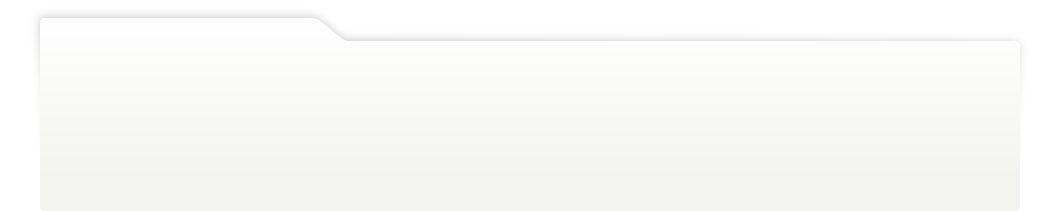
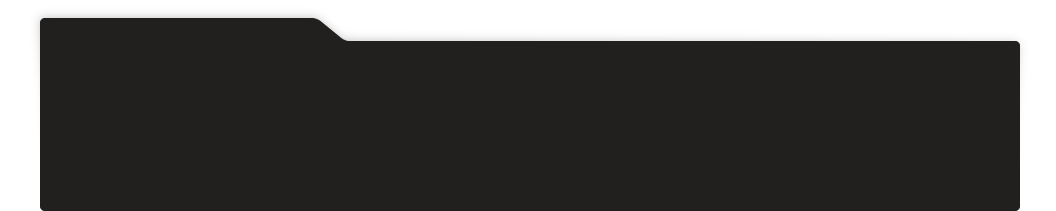
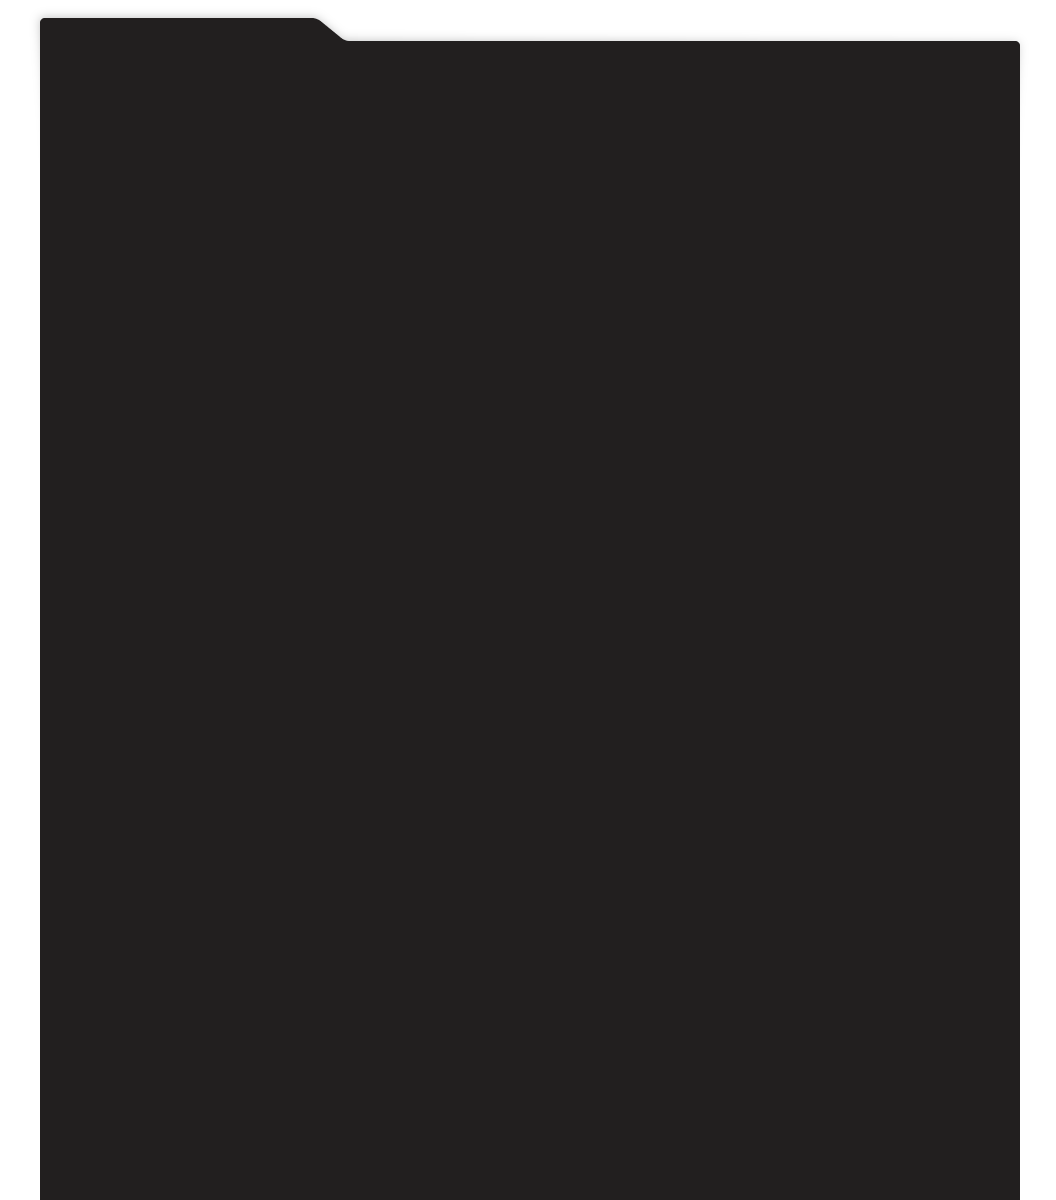
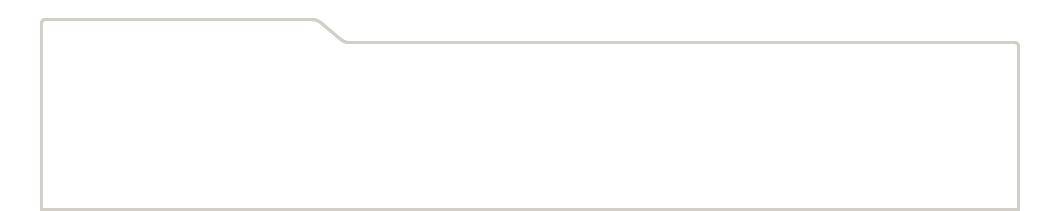
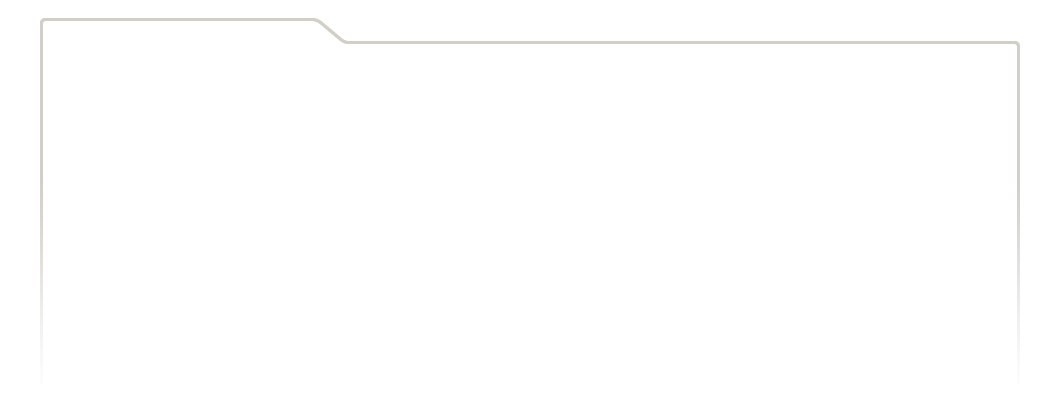
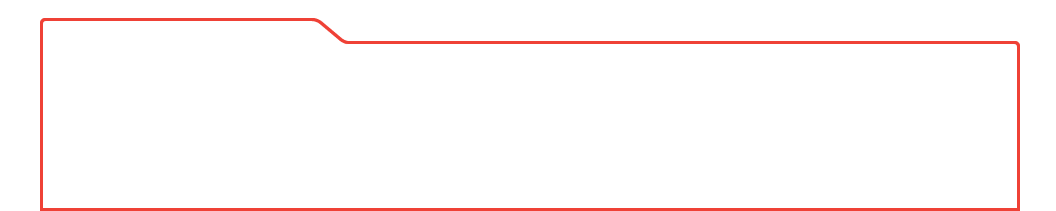
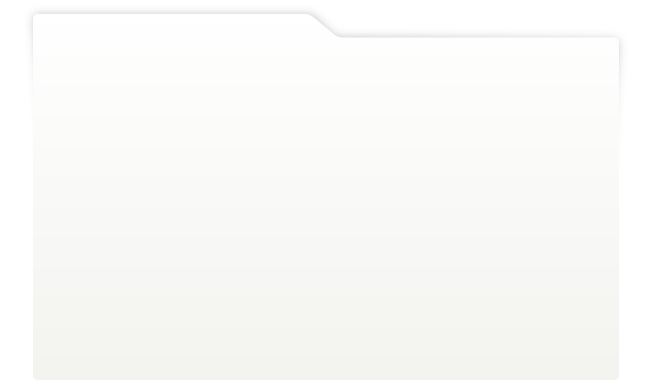
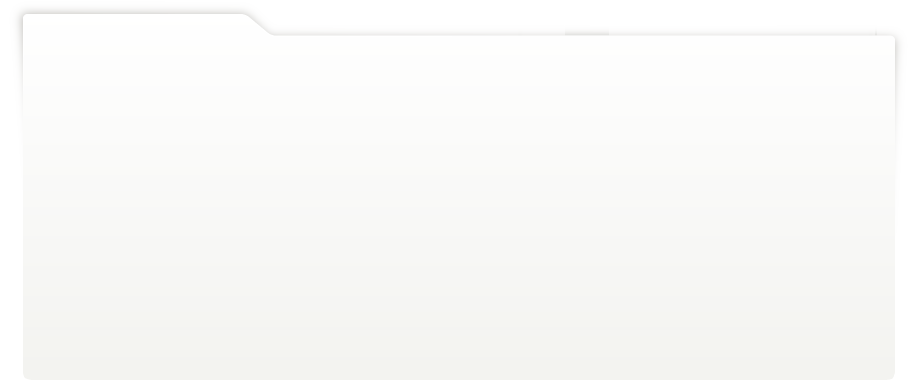
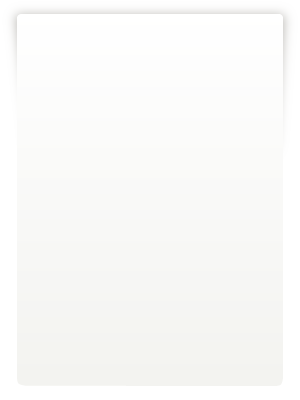
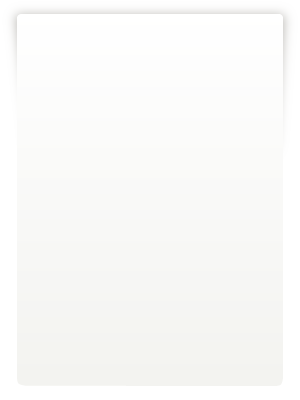
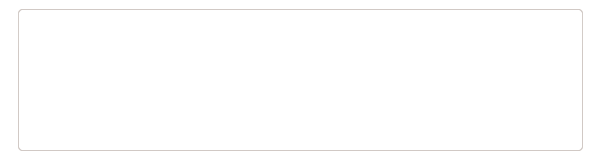
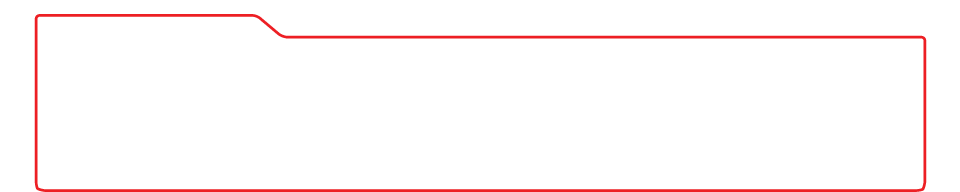
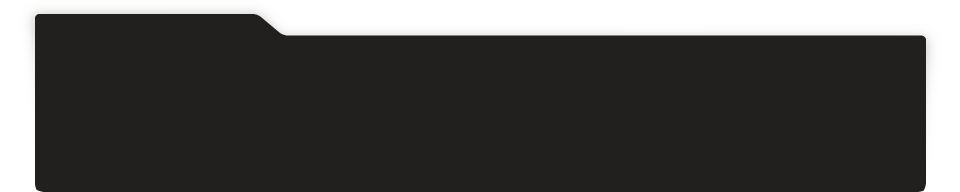
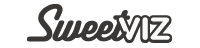
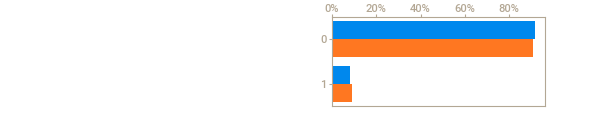
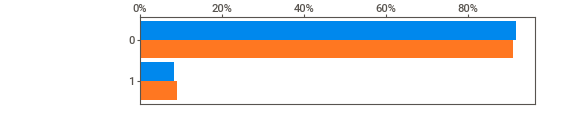
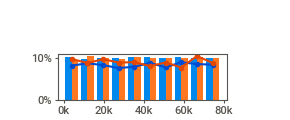
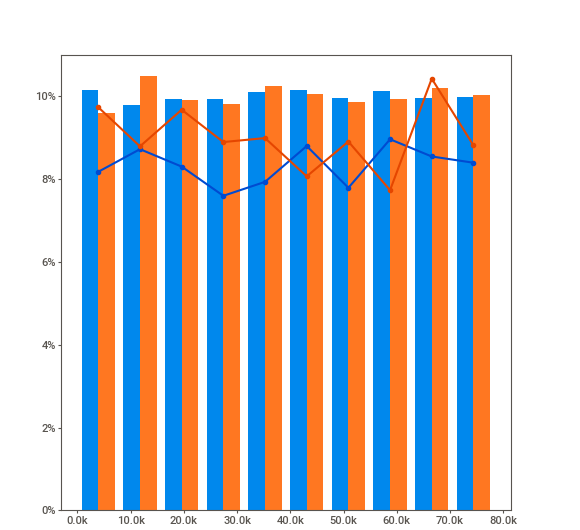
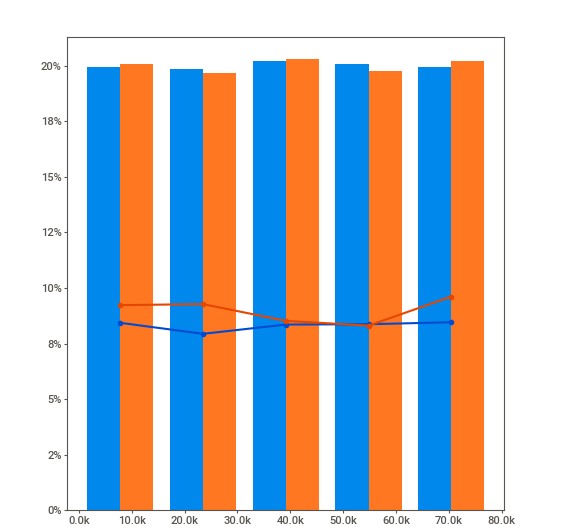
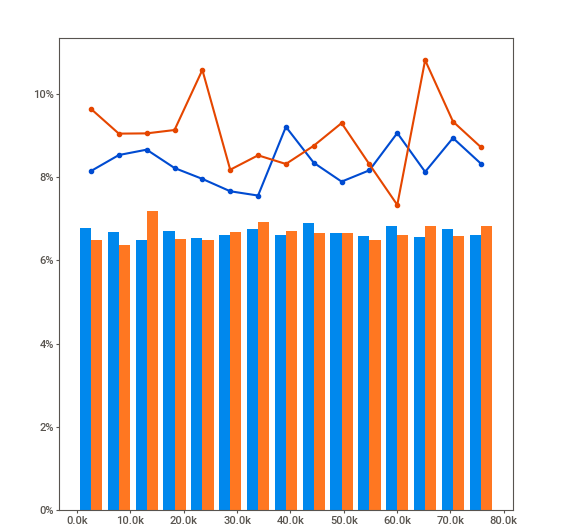
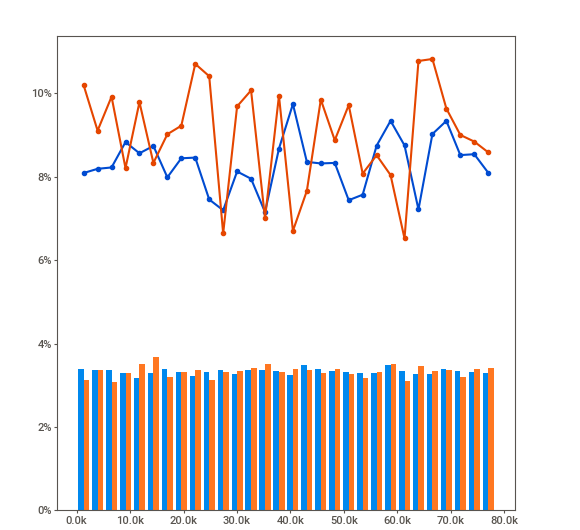
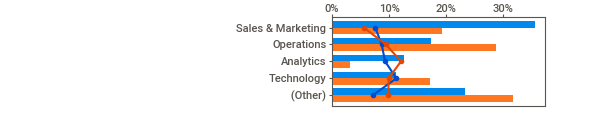
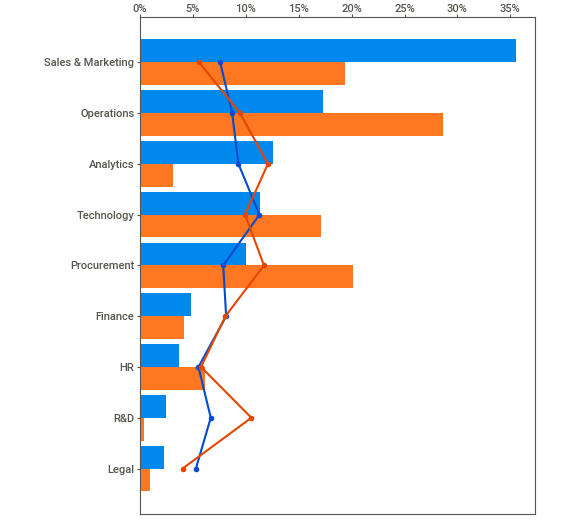
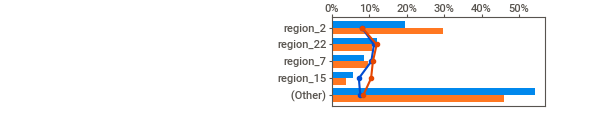
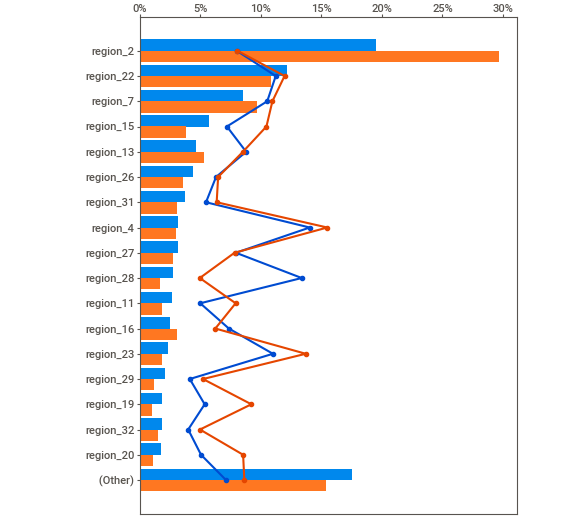
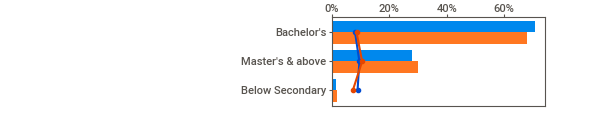
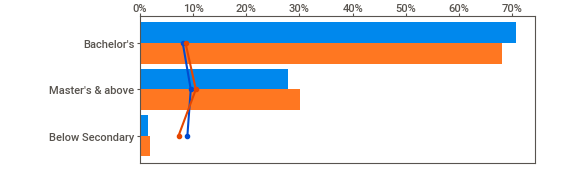
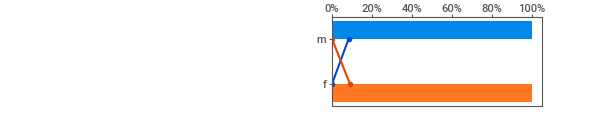
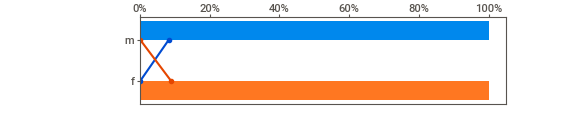
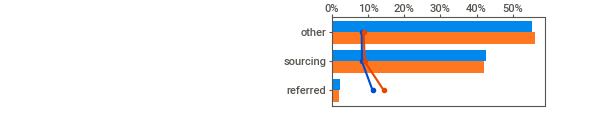
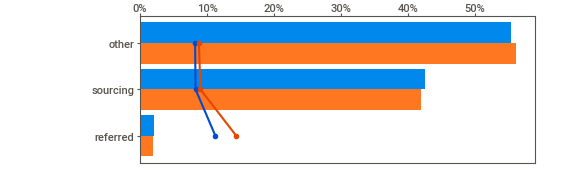
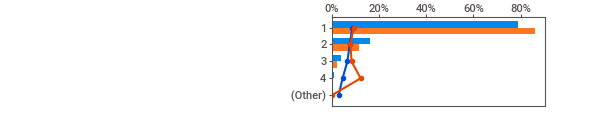
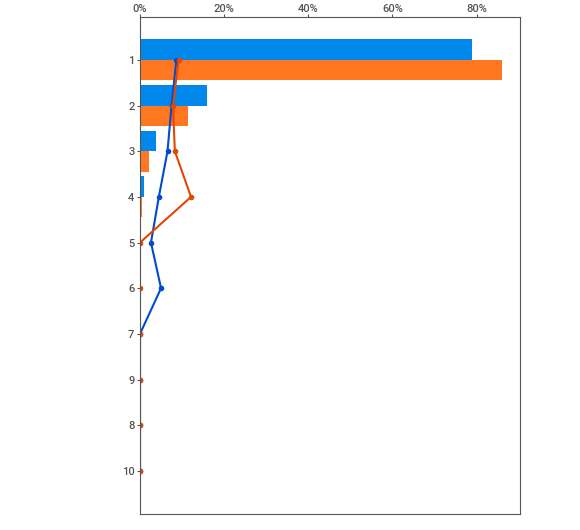
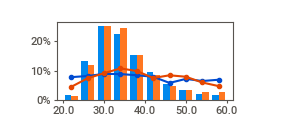
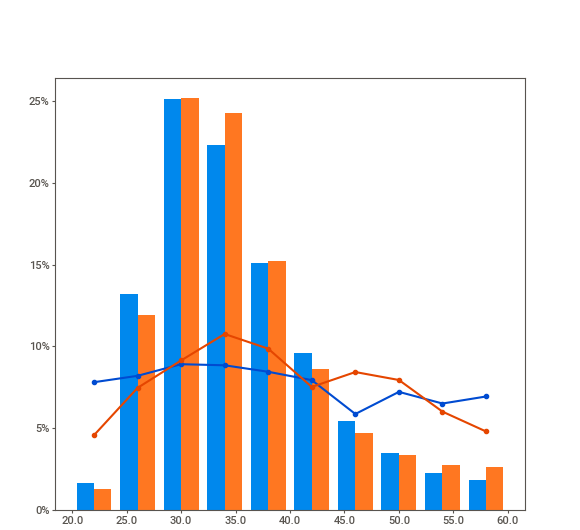
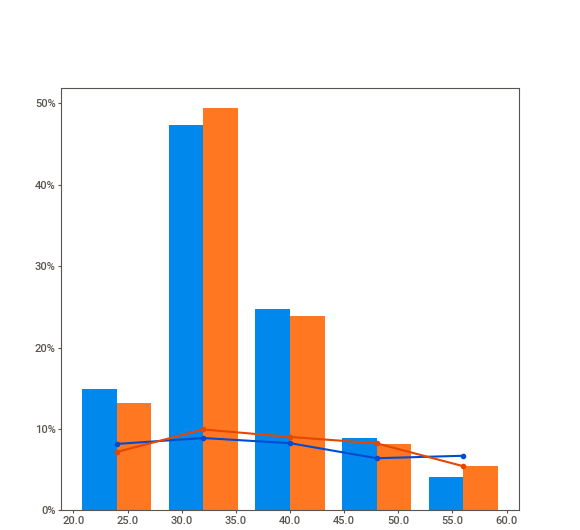
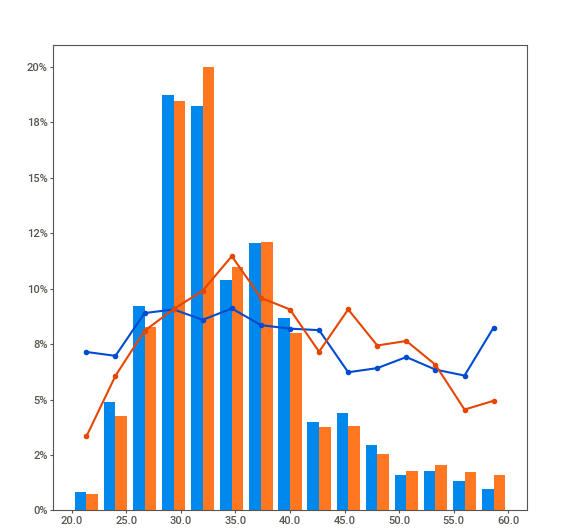
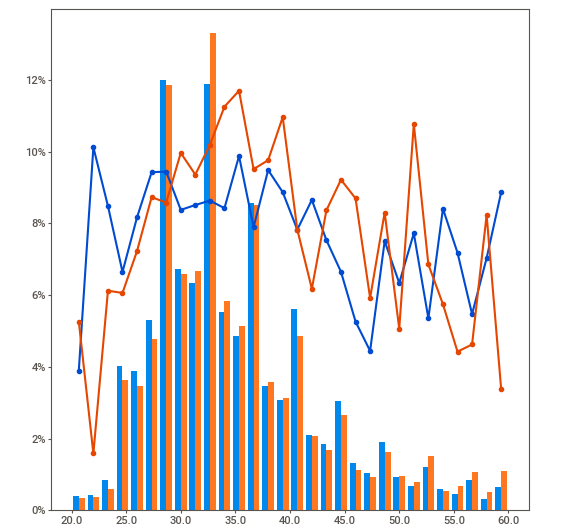
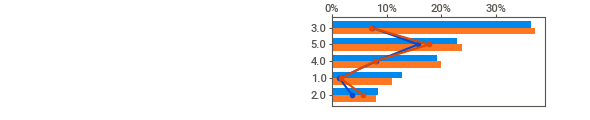
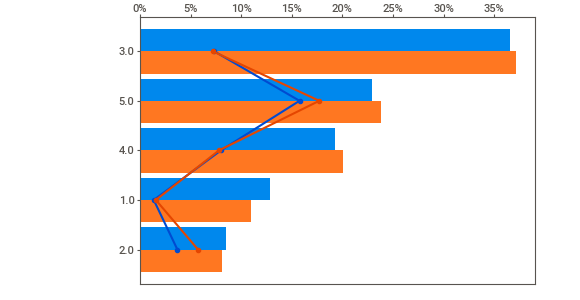
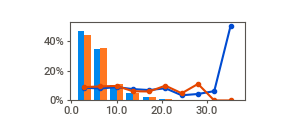
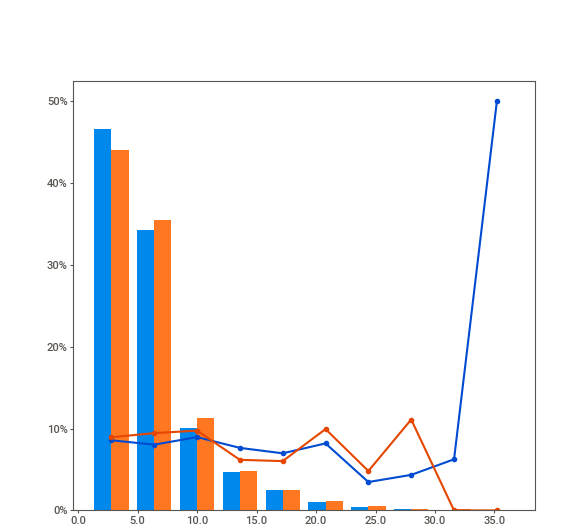
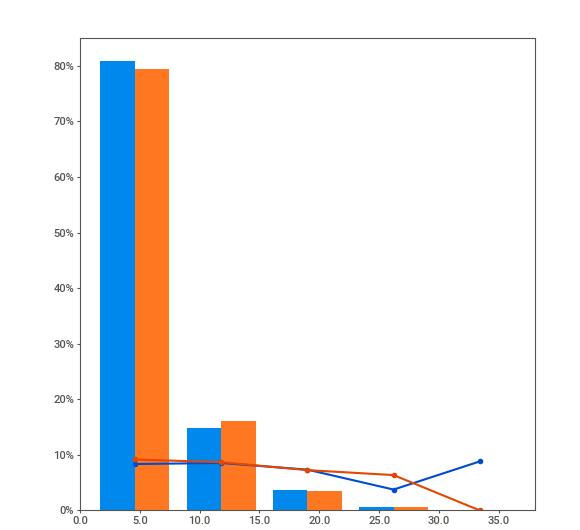
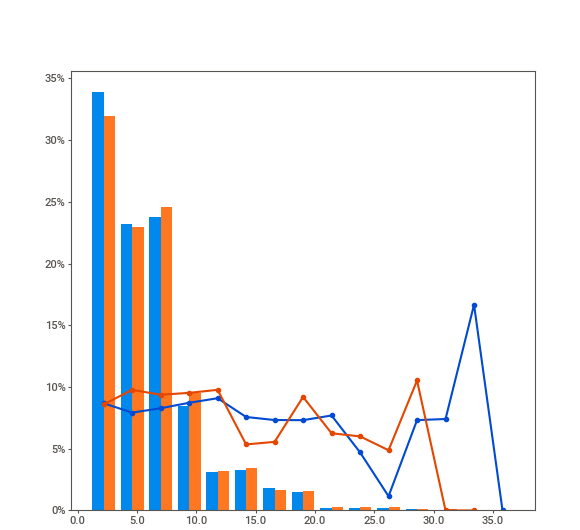
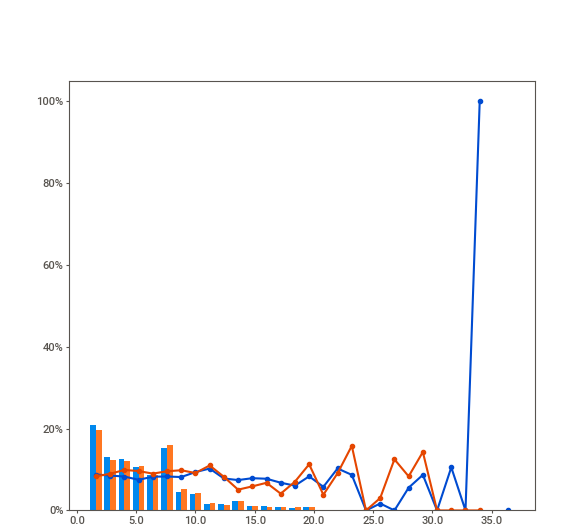
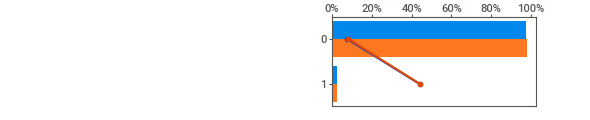
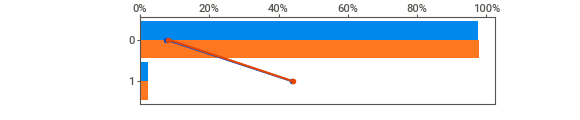
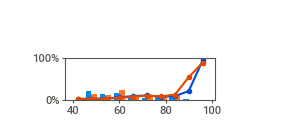
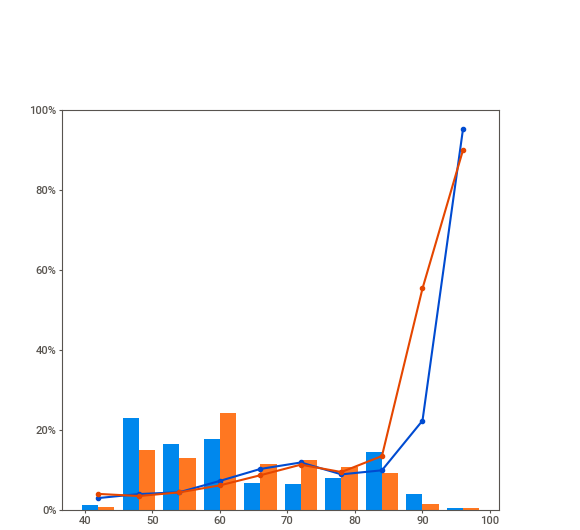
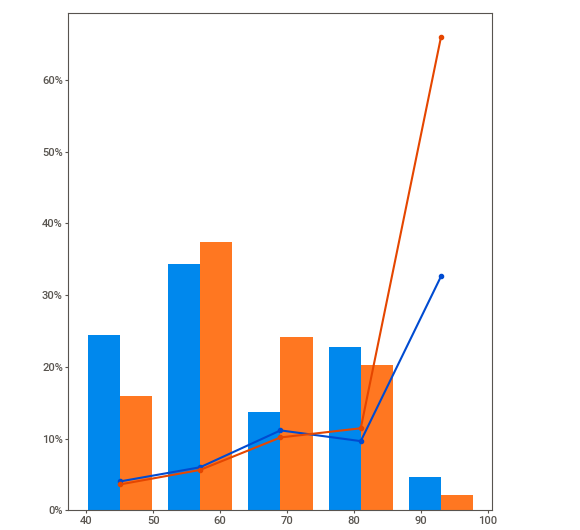
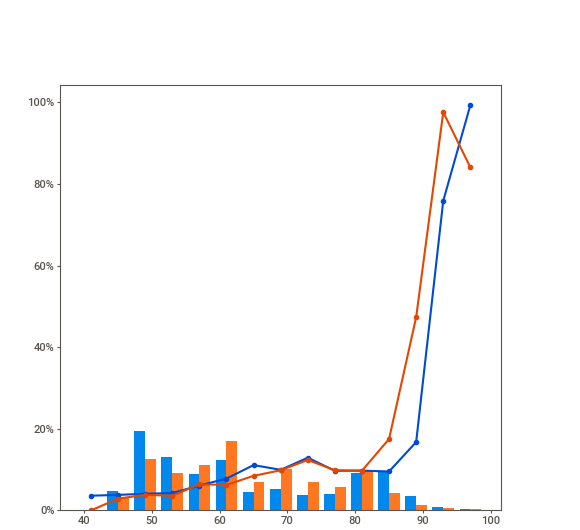
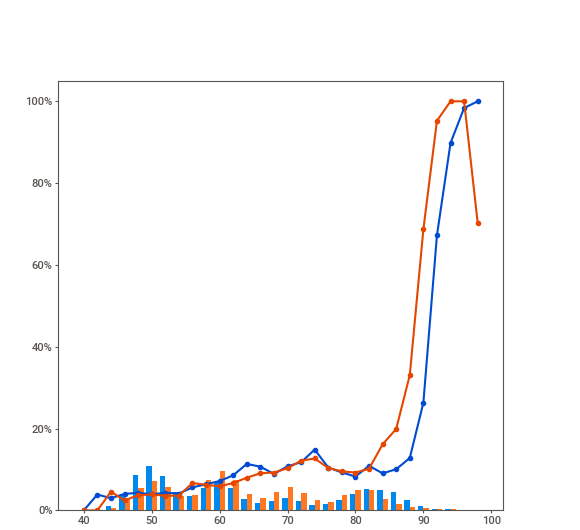
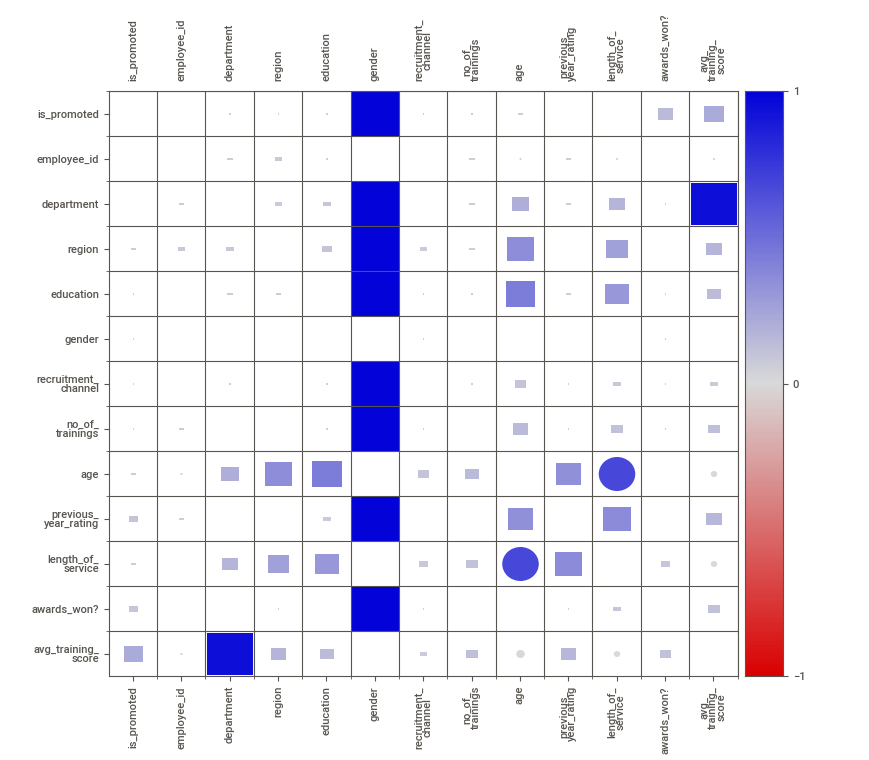
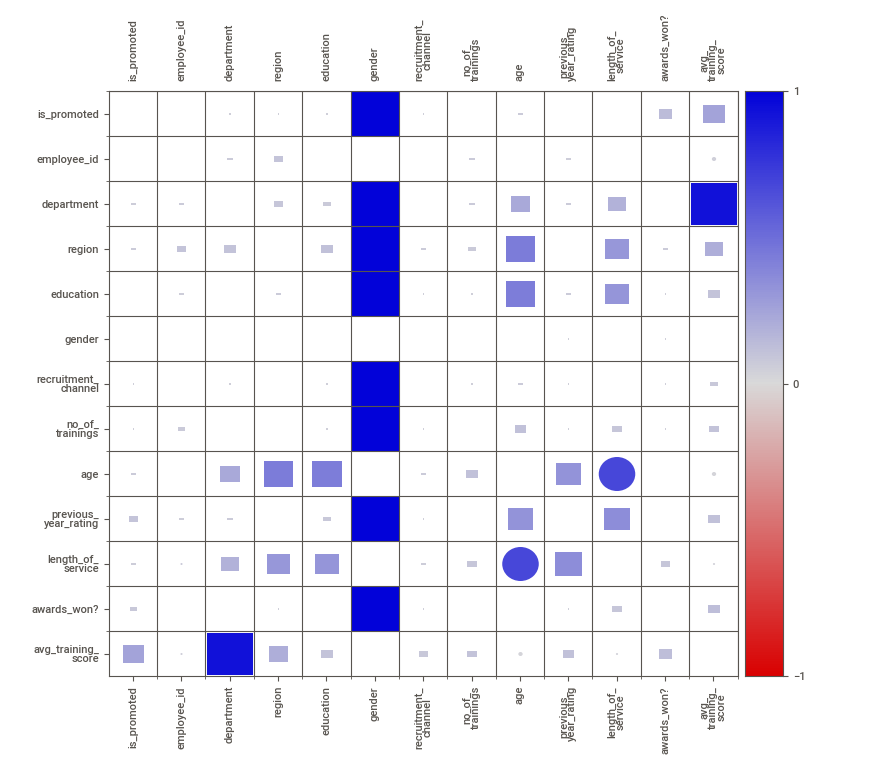

In [ ]:

# Paso 3: SweetViz comparando dos subconjuntos según la variable gender (booleana: m = True), con is_promoted como objetivo
reporte_sv = sv.compare_intra(info, info["gender"] == "m", ["Hombres (m)", "Mujeres (f)"], target_feat="is_promoted")
reporte_sv.show_notebook(w="100%", h=800, scale=None, layout="widescreen")      # incrustado en la libreta



**Interpretación.** SweetViz divide el conjunto en **hombres (38,496; 70.2 %)** y **mujeres (16,312; 29.8 %)** y compara cada variable entre ambos grupos, con `is_promoted` como objetivo. Según los datos, la tasa de promoción es **8.3 % en hombres y 9.0 % en mujeres**, es decir, 0.7 puntos más alta en mujeres, y la edad media (34.7 vs 35.0 años) y el puntaje promedio de capacitación (63.2 vs 63.9) son casi idénticos. Es decir, **no hay señal de que se promueva más a los hombres**; los dos grupos son parecidos. No probé si esa diferencia de 0.7 puntos es estadísticamente significativa, por lo que no la interpreto como un efecto real. La advertencia de equidad que sí aplica es otra: `gender` entra como predictor del modelo (ver conclusiones).


4. Elimina los registros con información faltante (`NaN`) y la columna `employee_id` por no tener aportación en la predicción.

In [ ]:

# Paso 4: valores faltantes y columna sin aporte predictivo
print("Valores faltantes por columna (antes):"); print(info.isna().sum()[info.isna().sum() > 0].to_string())
# ¿Qué tienen en común los faltantes de previous_year_rating?
print("\nAntigüedad de quienes no tienen calificación previa:", info.loc[info["previous_year_rating"].isna(), "length_of_service"].unique())
n_antes = len(info)
info = info.dropna().drop(columns="employee_id")       # se modifica info (no se vuelve a leer el archivo)
print(f"\nFilas: {n_antes:,} -> {len(info):,}  (eliminadas: {n_antes - len(info):,}, {1 - len(info) / n_antes:.1%})")
print("Columnas restantes:", list(info.columns))
print("Nulos restantes:", int(info.isna().sum().sum()))


Valores faltantes por columna (antes):
education               2409
previous_year_rating    4124

Antigüedad de quienes no tienen calificación previa: [1]

Filas: 54,808 -> 48,660  (eliminadas: 6,148, 11.2%)
Columnas restantes: ['department', 'region', 'education', 'gender', 'recruitment_channel', 'no_of_trainings', 'age', 'previous_year_rating', 'length_of_service', 'awards_won?', 'avg_training_score', 'is_promoted']
Nulos restantes: 0



**Interpretación.** Se eliminan **6,148 registros (11.2 %)** y quedan **48,660** sin ningún NaN, más 11 columnas predictoras y la objetivo (se quita `employee_id`, que es solo un identificador).

**Los faltantes de `previous_year_rating` no son aleatorios:** los 4,124 empleados sin calificación previa tienen exactamente **1 año de antigüedad**, es decir, son empleados que aún no habían sido evaluados un año antes. Eliminarlos tiene una consecuencia: **el modelo resultante no se entrena con empleados de primer año** y, por lo tanto, no debería usarse para predecir su promoción sin otra estrategia (por ejemplo, tratar "sin calificación" como una categoría en lugar de borrar la fila). Se hace así porque el reto lo pide.


# Obtención de un modelo de ML con H2O

5. Convierte el dataframe a un objeto H2OFrame y observa la distribución de la variable `is_promoted` para identificar si hay desbalance de clases.

Checking whether there is an H2O instance running at http://localhost:54321. connected.


H2O_cluster_uptime:,2 hours 12 mins
H2O_cluster_timezone:,Etc/UTC
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,2 months and 4 days
H2O_cluster_name:,H2O_from_python_unknownUser_yy7uvs
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,3.957 Gb
H2O_cluster_total_cores:,2
H2O_cluster_allowed_cores:,2
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+
{'department': 'enum', 'region': 'enum', 'education': 'enum', 'gender': 'enum', 'recruitment_channel': 'enum', 'no_of_trainings': 'int', 'age': 'int', 'previous_year_rating': 'int', 'length_of_service': 'int', 'awards_won?': 'int', 'avg_training_score': 'int', 'is_promoted': 'enum'}


,is_promoted,Count,porcentaje
0,0,44428,91.3
1,1,4232,8.7


Razón no promovidos : promovidos = 10.5 : 1


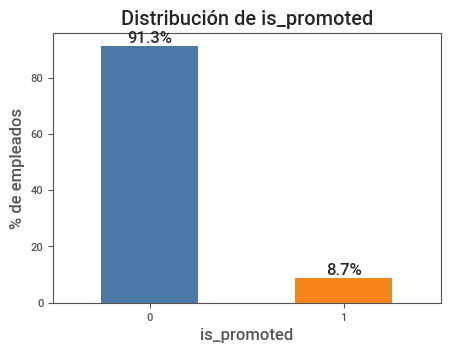

In [ ]:

# Paso 5: DataFrame -> H2OFrame y distribución de la variable objetivo
h2o.init(nthreads=-1, max_mem_size="4G")
h2o.no_progress()                                        # sin barras de progreso (la salida queda limpia)
datos_h2o = h2o.H2OFrame(info)
datos_h2o["is_promoted"] = datos_h2o["is_promoted"].asfactor()      # clasificación (no regresión)
print(datos_h2o.types)

dist = datos_h2o["is_promoted"].table().as_data_frame()
dist["porcentaje"] = (100 * dist["Count"] / dist["Count"].sum()).round(2)
display(dist)
ax = dist.set_index("is_promoted")["porcentaje"].plot(kind="bar", color=["#4C78A8", "#F58518"], rot=0, figsize=(5, 3.5))
ax.set_ylabel("% de empleados"); ax.set_title("Distribución de is_promoted")
for p in ax.patches: ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
print(f"Razón no promovidos : promovidos = {dist['Count'][0] / dist['Count'][1]:.1f} : 1")



**Interpretación.** Sí hay **desbalance de clases**: de 48,660 empleados, **44,428 (91.3 %) no fueron promovidos y 4,232 (8.7 %) sí**, una razón de 10.5 a 1. Consecuencias para lo que sigue:

- Un modelo que **siempre responde "no promovido" ya tendría 91.3 % de accuracy** sin aprender nada. Cualquier modelo debe compararse contra esa referencia.
- La métrica que pide el reto, **accuracy, favorece a quien ignora la clase minoritaria**; por eso, además del accuracy, se reportan precisión, recall, F1 y AUC de la clase "promovido".
- Por eso, en H2O y en PyCaret se activa el **balanceo de clases** (`balance_classes=True` y `fix_imbalance=True`), como pide la rúbrica; en el siguiente apartado se comprueba cuánto cambió realmente.
- H2O trató `is_promoted` como **categórica** (`asfactor`), de modo que hace clasificación y no regresión.


6. Divide el conjunto en entrenamiento y prueba, usando una distribución de 80:20. Utiliza el parámetro `seed=1` para garantizar reproducibilidad. Separa los predictores y la variable objetivo `is_promoted`.

In [ ]:

# Paso 6: partición 80:20 con seed=1; predictores y variable objetivo
entrenamiento_h2o, prueba_h2o = datos_h2o.split_frame(ratios=[0.8], seed=1)
y = "is_promoted"
x = [col for col in datos_h2o.columns if col != y]
print("Entrenamiento:", entrenamiento_h2o.nrows, "| Prueba:", prueba_h2o.nrows)
print("Predictores:", x)
print("\n% promovidos -> entrenamiento:", round(100 * entrenamiento_h2o[y].asnumeric().mean()[0], 2), "| prueba:", round(100 * prueba_h2o[y].asnumeric().mean()[0], 2))


Entrenamiento: 38979 | Prueba: 9681
Predictores: ['department', 'region', 'education', 'gender', 'recruitment_channel', 'no_of_trainings', 'age', 'previous_year_rating', 'length_of_service', 'awards_won?', 'avg_training_score']

% promovidos -> entrenamiento: 8.68 | prueba: 8.77



**Interpretación.** La partición 80:20 con `seed=1` deja **38,979 empleados para entrenamiento y 9,681 para prueba**, con 11 predictores. La proporción de promovidos es casi igual en ambos (8.68 % y 8.77 %), pero `split_frame` es una partición aleatoria **sin estratificar**, de modo que esa similitud es resultado del azar y con otra semilla podría variar un poco más.


7. Ejecuta el autoaprendizaje utilizando el parámetro `seed=1` y limita el tiempo de ejecución a 5 minutos. Obtén el `accuracy` en el conjunto de prueba.

In [ ]:

# Paso 7: H2O AutoML con seed=1, límite de 5 minutos (300 s) y balanceo de clases (hay 10.5 : 1 en contra de la clase "promovido")
aml = H2OAutoML(max_runtime_secs=300, seed=1, balance_classes=True, sort_metric="AUC")
aml.train(x=x, y=y, training_frame=entrenamiento_h2o)
display(aml.leaderboard.head(10).as_data_frame())
print("Modelo líder:", aml.leader.model_id)


,model_id,auc,logloss,aucpr,mean_per_class_error,rmse,mse
0,StackedEnsemble_AllModels_1_AutoML_2_20261015_...,0.815626,0.207520,0.547833,0.307863,0.231559,0.053620
1,StackedEnsemble_BestOfFamily_2_AutoML_2_202610...,0.813919,0.208619,0.545745,0.309165,0.232286,0.053957
2,StackedEnsemble_BestOfFamily_3_AutoML_2_202610...,0.813836,0.208317,0.546255,0.312722,0.232021,0.053834
3,StackedEnsemble_BestOfFamily_1_AutoML_2_202610...,0.813693,0.208392,0.545225,0.310350,0.231948,0.053800
4,GBM_3_AutoML_2_20261015_201211,0.807397,0.230843,0.521421,0.310068,0.251146,0.063074
5,GBM_1_AutoML_2_20261015_201211,0.806928,0.224092,0.529836,0.315385,0.238334,0.056803
6,GBM_2_AutoML_2_20261015_201211,0.806919,0.230005,0.520054,0.317301,0.250410,0.062705
7,XGBoost_2_AutoML_2_20261015_201211,0.797975,0.397078,0.524671,0.313244,0.353982,0.125303
8,GBM_4_AutoML_2_20261015_201211,0.797420,0.238650,0.509055,0.319583,0.256214,0.065646
9,XGBoost_3_AutoML_2_20261015_201211,0.792581,0.520786,0.482970,0.327129,0.412534,0.170184


Modelo líder: StackedEnsemble_AllModels_1_AutoML_2_20261015_201211


In [ ]:
# Accuracy del modelo líder en el conjunto de PRUEBA (con las clases que predice el modelo, sin mirar la prueba para elegir el umbral)
pred_h2o = aml.leader.predict(prueba_h2o).as_data_frame()["predict"].astype(str).to_numpy()
real_h2o = prueba_h2o[y].as_data_frame()[y].astype(str).to_numpy()
acc_h2o = float((pred_h2o == real_h2o).mean())
acc_base_h2o = float((real_h2o == "0").mean())
tp = int(((pred_h2o == "1") & (real_h2o == "1")).sum()); fp = int(((pred_h2o == "1") & (real_h2o == "0")).sum())
fn = int(((pred_h2o == "0") & (real_h2o == "1")).sum()); tn = int(((pred_h2o == "0") & (real_h2o == "0")).sum())
prec = tp / (tp + fp) if tp + fp else 0.0; rec = tp / (tp + fn); f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
rendimiento = aml.leader.model_performance(prueba_h2o)
print(f"ACCURACY en prueba (H2O): {acc_h2o:.4f}")
print(f"Referencia: siempre predecir 'no promovido' -> accuracy = {acc_base_h2o:.4f}")
print(f"Clase 'promovido': precisión = {prec:.3f} | recall = {rec:.3f} | F1 = {f1:.3f} | AUC = {rendimiento.auc():.3f}")
print(pd.DataFrame([[tn, fp], [fn, tp]], index=["Real: no promovido", "Real: promovido"], columns=["Pred: no promovido", "Pred: promovido"]))

ACCURACY en prueba (H2O): 0.9361
Referencia: siempre predecir 'no promovido' -> accuracy = 0.9123
Clase 'promovido': precisión = 0.757 | recall = 0.399 | F1 = 0.523 | AUC = 0.821
                    Pred: no promovido  Pred: promovido
Real: no promovido                8723              109
Real: promovido                    510              339


**Interpretación del accuracy en prueba (9,681 empleados).**

- **Accuracy = 0.9361**, contra **0.9123** del modelo que nunca promueve: una mejora de **2.4 puntos porcentuales**. El líder fue un *stacked ensemble* (`StackedEnsemble_AllModels_1`, AUC en validación cruzada 0.816).
- El accuracy oculta lo importante. De los **849 empleados realmente promovidos, el modelo detecta 339 (recall 39.9 %) y se le escapan 510**. Cuando dice "promovido" acierta 75.7 % de las veces (precisión; solo 109 falsas alarmas). El F1 de la clase "promovido" es 0.523 y el AUC 0.821.
- Es un modelo **conservador**: casi no se equivoca al promover, pero deja pasar a seis de cada diez candidatos que sí fueron promovidos. Para identificar candidatos elegibles eso es limitado.
- Se activó `balance_classes=True`, como pide el reto, pero **no hice una corrida sin balancear para comparar**, así que no puedo medir su efecto. Lo que sí se ve es que el recall sigue por debajo de 40 % pese al balanceo; mi hipótesis (no verificada) es que el límite está en la información que aportan las variables y no solo en el desbalance.

# **Obtención de un modelo de ML con PyCaret**

8. Sin leer nuevamente el archivo (para no perder los cambios de la pregunta 4), divide el dataframe `info` en conjuntos de entrenamiento y prueba (80:20). Utiliza el parámetro `random_state=1` para garantizar reproducibilidad.

In [ ]:

# Paso 8: partición 80:20 de info (ya sin NaN ni employee_id) con random_state=1
entrenamiento_pc, prueba_pc = train_test_split(info, test_size=0.2, random_state=1)
print("Entrenamiento:", entrenamiento_pc.shape, "| Prueba:", prueba_pc.shape)
print("% promovidos -> entrenamiento:", round(100 * entrenamiento_pc["is_promoted"].mean(), 2), "| prueba:", round(100 * prueba_pc["is_promoted"].mean(), 2))


Entrenamiento: (38928, 12) | Prueba: (9732, 12)
% promovidos -> entrenamiento: 8.67 | prueba: 8.8



**Interpretación.** `info` (ya sin NaN ni `employee_id`) se divide en **38,928 empleados de entrenamiento y 9,732 de prueba**, con 8.67 % y 8.80 % de promovidos. Se usa `random_state=1`, sin estratificar, tal como pide el reto. Esta partición **no es la misma que la de H2O** (9,732 vs 9,681 empleados de prueba), por lo que las métricas de las dos plataformas se calcularon sobre conjuntos de prueba distintos y no son estrictamente comparables entre sí.


9. Ejecuta el autoaprendizaje con parámetros equivalentes a los que usaste en H2O y optimiza el mejor modelo con la métrica `accuracy`.

In [ ]:

# Paso 9: PyCaret. Equivalencias con H2O: seed=1 -> session_id=1 ; balance_classes=True -> fix_imbalance=True (SMOTE) ;
# 5 minutos -> budget_time=5 ; métrica -> Accuracy. fix_imbalance solo remuestrea el entrenamiento, no la prueba.
experimento = setup(data=entrenamiento_pc, test_data=prueba_pc, target="is_promoted", session_id=1, fix_imbalance=True)


,Description,Value
0,Session id,1
1,Target,is_promoted
2,Target type,Binary
3,Original data shape,"(48660, 12)"
4,Transformed data shape,"(80836, 24)"
5,Transformed train set shape,"(71104, 24)"
6,Transformed test set shape,"(9732, 24)"
7,Numeric features,6
8,Categorical features,5
9,Preprocess,True


In [ ]:
# Compara modelos durante 5 minutos como máximo, ordenados por Accuracy
mejor_modelo = compare_models(sort="Accuracy", budget_time=5)
mejor_modelo

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
rf,Random Forest Classifier,0.9299,0.7717,0.3021,0.7346,0.4280,0.3975,0.4426,9.8670
dt,Decision Tree Classifier,0.8749,0.6458,0.3688,0.3128,0.3382,0.2697,0.2710,1.0800
lr,Logistic Regression,0.7574,0.7951,0.6700,0.2138,0.3241,0.2217,0.2757,7.4510
ridge,Ridge Classifier,0.7544,0.7915,0.6641,0.2104,0.3195,0.2163,0.2697,0.4930
knn,K Neighbors Classifier,0.7395,0.6572,0.4810,0.1622,0.2425,0.1296,0.1578,4.2790
svm,SVM - Linear Kernel,0.6412,0.7685,0.6982,0.1972,0.2831,0.1693,0.2240,5.7430
qda,Quadratic Discriminant Analysis,0.6224,0.6438,0.5851,0.1479,0.2271,0.1034,0.1359,0.5400
nb,Naive Bayes,0.5043,0.6914,0.7669,0.1228,0.2117,0.0731,0.1392,0.5020


Processing:   0%|          | 0/65 [00:00<?, ?it/s]

RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=None, max_features='sqrt',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_samples_leaf=1,
                       min_samples_split=2, min_weight_fraction_leaf=0.0,
                       monotonic_cst=None, n_estimators=100, n_jobs=-1,
                       oob_score=False, random_state=1, verbose=0,
                       warm_start=False)

**Configuración equivalente a H2O:** `session_id=1` (seed=1), `fix_imbalance=True` (balanceo de clases con SMOTE, aplicado solo al entrenamiento), `budget_time=5` (5 minutos) y `sort="Accuracy"`. Se usa la misma partición 80:20 del paso 8 (`test_data`).

**Interpretación de `compare_models` (10 pliegues, sobre entrenamiento).** Dentro del presupuesto de 5 minutos PyCaret alcanzó a evaluar **8 modelos**. El mejor por accuracy es **Random Forest (0.9299)**, con AUC 0.772, recall 0.302, precisión 0.735 y F1 0.428. Le siguen Decision Tree (0.8749), Regresión Logística (0.7574), Ridge (0.7544), KNN (0.7395), SVM lineal (0.6412), QDA (0.6224) y Naive Bayes (0.5043).

Observaciones: (1) la referencia de "nunca promover" es ≈ **0.912**; **solo Random Forest la supera**, los otros siete quedan por debajo; (2) con SMOTE, los modelos lineales y probabilísticos **ganan recall** (regresión logística 0.67, SVM 0.70, Naive Bayes 0.77) pero **su accuracy cae mucho**, por eso al ordenar por accuracy pierden frente a Random Forest; es el compromiso entre accuracy y recall; (3) por el límite de tiempo no se evaluaron otros modelos del catálogo de PyCaret (por ejemplo los de boosting), así que "mejor modelo" significa el mejor **de los 8 evaluados**.


In [ ]:
# Optimiza el mejor modelo con la métrica Accuracy (búsqueda aleatoria con validación cruzada)
# choose_better=True: si el modelo ajustado no supera al original, PyCaret devuelve el original
modelo_optimizado = tune_model(mejor_modelo, optimize="Accuracy", choose_better=True)
modelo_optimizado

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9134,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000
1,0.9134,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000
2,0.9132,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000
3,0.9132,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000
4,0.9132,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000
5,0.9132,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000
6,0.9132,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000
7,0.9132,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000
8,0.9134,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000


Processing:   0%|          | 0/7 [00:00<?, ?it/s]

Fitting 10 folds for each of 10 candidates, totalling 100 fits


Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=None, max_features='sqrt',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_samples_leaf=1,
                       min_samples_split=2, min_weight_fraction_leaf=0.0,
                       monotonic_cst=None, n_estimators=100, n_jobs=-1,
                       oob_score=False, random_state=1, verbose=0,
                       warm_start=False)

**Interpretación de `tune_model`.** PyCaret probó 10 combinaciones de hiperparámetros con 10 pliegues cada una (100 ajustes), optimizando `Accuracy`. Con `choose_better=True`, PyCaret avisa: *"Original model was better than the tuned model, hence it will be returned"*, así que **el modelo final es el Random Forest original** (`n_estimators=100` y el resto de parámetros por defecto).

Ojo con la tabla de pliegues que aparece arriba: como indica el propio aviso, **corresponde al modelo ajustado, no al original**. Ese candidato ajustado obtuvo accuracy 0.9133, AUC 0.5000 y recall 0.0000 en todos los pliegues, lo que indica que terminó prediciendo siempre "no promovido" (equivale a la referencia de nunca promover) y por eso perdió frente al original (0.9299). Es decir, la búsqueda aleatoria **no encontró ninguna mejora**; lo reporto tal cual.


10. Verifica las métricas con el conjunto de prueba y utiliza `evaluate_model()` para mostrar la interfaz de usuario con detalles del modelo optimizado.


In [ ]:

# Paso 10: métricas con el conjunto de PRUEBA (predict_model sobre prueba_pc, que el entrenamiento no vio)
predicciones = predict_model(modelo_optimizado, data=prueba_pc)
metricas_prueba = pull()
display(metricas_prueba)
acc_base_pc = float((prueba_pc["is_promoted"] == 0).mean())
print(f"Referencia: siempre predecir 'no promovido' -> accuracy = {acc_base_pc:.4f}")


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.9317,0.7834,0.3306,0.7547,0.4598,0.4292,0.4712


,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
0,Random Forest Classifier,0.9317,0.7834,0.3306,0.7547,0.4598,0.4292,0.4712


Referencia: siempre predecir 'no promovido' -> accuracy = 0.9120


**Interpretación en el conjunto de prueba (9,732 empleados).**

| Métrica | Valor |
|---|---|
| Accuracy | **0.9317** (referencia "nunca promover": 0.9120) |
| AUC | 0.7834 |
| Precisión | 0.7547 |
| Recall | 0.3306 |
| F1 | 0.4598 |
| Kappa / MCC | 0.4292 / 0.4712 |

- Matriz de confusión: 8,784 verdaderos negativos, 92 falsos positivos, 573 falsos negativos y 283 verdaderos positivos. De los 856 promovidos reales detecta 283 (33 %).
- El accuracy de prueba (0.9317) es muy parecido al de validación cruzada (0.9299): **no hay señal de sobreajuste**. La mejora sobre la referencia es de **2.0 puntos porcentuales**.
- Patrón parecido al de H2O: **precisión alta (75 %) y recall bajo (33 %)**. Cuando el modelo señala a alguien casi siempre acierta, pero identifica a solo un tercio de los promovidos reales. Una posible causa es que el umbral estándar (0.5) es exigente con solo 8.7 % de positivos; es una hipótesis, no la probé.

In [ ]:
# Interfaz interactiva de PyCaret con los detalles del modelo optimizado
evaluate_model(modelo_optimizado)

interactive(children=(ToggleButtons(description='Plot Type:', icons=('',), options=(('Pipeline Plot', 'pipelin…

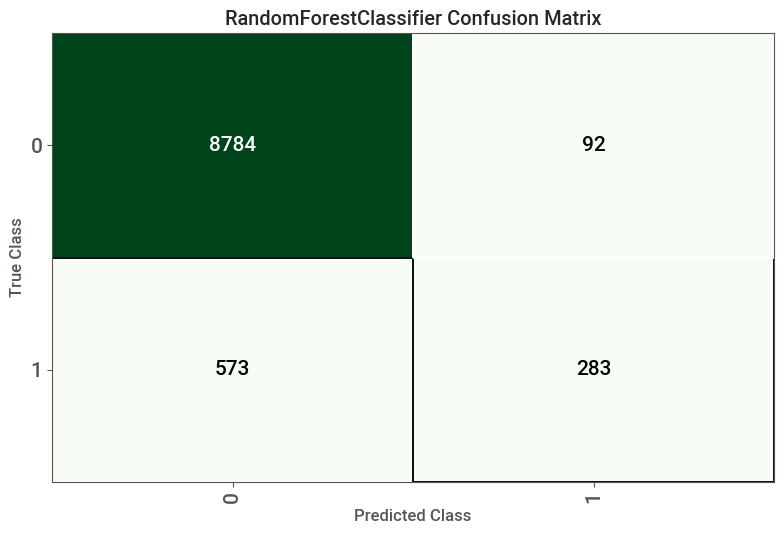

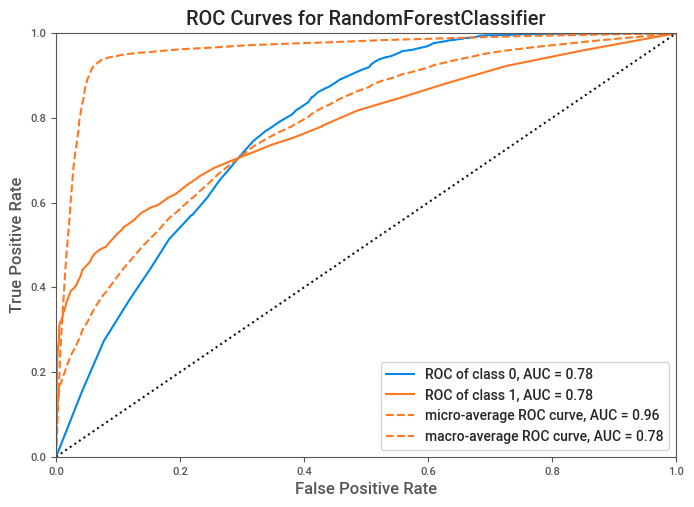

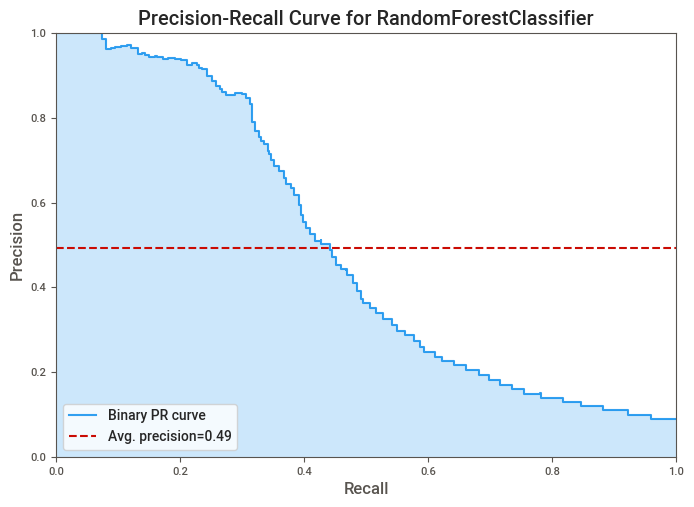

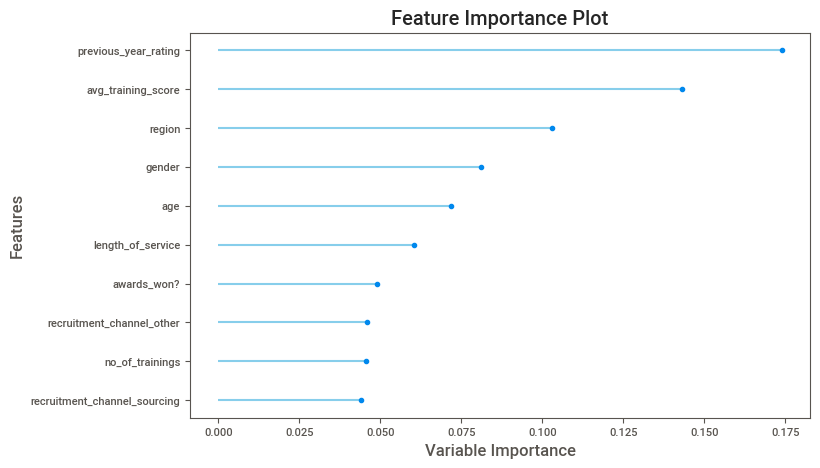

In [ ]:
# Gráficas estáticas de los mismos detalles (se conservan al guardar la libreta, a diferencia de los widgets)
for tipo in ["confusion_matrix", "auc", "pr", "feature"]:
    try:
        plot_model(modelo_optimizado, plot=tipo)
    except Exception as e:
        print(f"[{tipo}] no disponible para este modelo: {type(e).__name__}")


**Qué muestran los detalles del modelo.** `evaluate_model()` abre la interfaz interactiva de PyCaret (pestañas con matriz de confusión, curvas ROC y PR, importancia de variables, entre otras); esa interfaz **solo se muestra al ejecutar la libreta**, por eso debajo se agregan las mismas gráficas como imágenes que sí se conservan al guardar.

- **Curva ROC:** la AUC de la clase "promovido" es 0.78, igual que en la tabla de prueba. La curva *micro-average* (0.96) **no debe leerse como calidad del modelo**: está inflada por la clase mayoritaria.
- **Importancia de variables (Random Forest):** lideran `previous_year_rating` (≈ 0.17) y `avg_training_score` (≈ 0.14), seguidas de `region` (≈ 0.10). `gender` aparece en cuarto lugar (≈ 0.08), antes que `age` y `length_of_service`; `awards_won?` queda en séptimo (≈ 0.05).
- **Cuidado al interpretarla:** esta importancia se basa en cuánto reducen la impureza las divisiones del árbol y **favorece a variables con muchas categorías o continuas** (como `region`). Una variable rara pero muy informativa, como `awards_won?`, puede salir infravalorada: en los datos crudos los premiados se promueven mucho más (44 % frente a 7.7 %) y aun así queda en séptimo lugar.


# Conclusiones


**Resultados.** Las dos plataformas llegan a un accuracy similar en prueba: **H2O 0.936** (líder: *stacked ensemble*) y **PyCaret 0.932** (Random Forest), contra ≈ 0.912 de la referencia que nunca promueve. Esas cifras se calcularon sobre conjuntos de prueba distintos (9,681 y 9,732 empleados), así que **no puedo declarar a una plataforma superior a la otra**; ambas están en el mismo nivel. Lo importante es que el accuracy exagera la calidad: los modelos **detectan solo 33 a 40 % de los empleados promovidos** (precisión de ≈ 75 %, recall bajo) y el AUC es 0.78 a 0.82. Ambas plataformas se ejecutaron con balanceo de clases, pero no hice corridas sin balancear, así que no puedo cuantificar su efecto.

**Qué dicen los datos** (calculado directamente sobre el archivo original): se promueve más a quien ganó premios (44 % frente a 7.7 %), a quien tuvo calificación 5 el año anterior (16.4 % frente a 1.4 % con calificación 1) y a quien tiene puntaje de capacitación superior a 80 (17.3 % frente a 3.9 % con 50 o menos). Es coherente con que `previous_year_rating` y `avg_training_score` encabecen la importancia de variables en PyCaret.

**Limitaciones y qué mejoraría en un siguiente ciclo**
1. **Elegir la métrica según el uso.** Si el objetivo es identificar candidatos elegibles, optimizar **F1, recall o AUC-PR** y ajustar el umbral de decisión (por debajo de 0.5) probablemente subiría el recall. No lo probé.
2. **Eliminar los NaN descarta a los empleados de primer año** (4,124 casos sin calificación previa); tratarlos como categoría propia evitaría perder esa población.
3. **Equidad:** `gender` aparece en cuarto lugar de importancia y `age` en quinto. Antes de usar el modelo para decidir sobre personas habría que revisar si es legal y justo usarlas; excluirlas es una prueba sencilla para ver cuánto se pierde.
4. **Reproducibilidad:** con límite de tiempo, H2O no garantiza resultados idénticos entre ejecuciones (en dos corridas mías el accuracy de prueba pasó de 0.9355 a 0.9361); para un resultado exactamente reproducible habría que fijar el número de modelos en lugar del tiempo.
5. **Comparabilidad:** usar la misma partición en H2O y PyCaret permitiría comparar las plataformas con las mismas filas.
6. **Cobertura de modelos:** el presupuesto de 5 minutos limitó a PyCaret a 8 modelos; con más tiempo podrían entrar modelos de boosting y cambiar el ganador.
